# Analyse musicale classique (MIR) : beat, tempo, tonalité, accords

Les carnets [04-15-MERT2](04-15-MERT2-Music-Understanding.ipynb) et [04-16-SheetSage2](04-16-SheetSage2-Audio-To-Score.ipynb) couvrent le MIR *neuronal* : des modèles entraînés sur de grandes collections. Ce carnet couvre le socle **classique** (signal + statistiques), celui qui a précédé et qui accompagne encore le deep learning en production : on estime le **tempo** et les **beats**, la **tonalité** et la **grille d'accords** d'un extrait à partir de descripteurs DSP — enveloppe d'onsets, chromagramme — et d'un peu de statistique.

La démarche est volontairement inversée par rapport aux carnets neuronaux :

1. on **synthétise** d'abord un extrait dont on connaît *exactement* le tempo, la tonalité et la grille — le MIR est un problème inverse, et on ne peut mesurer une estimation que contre une vérité terrain ;
2. on applique les algorithmes classiques (beat tracking, profils de Krumhansl–Schmuckler, templates d'accords) et on **chiffre l'erreur** ;
3. on termine sur de la **vraie musique** (exemples redistribuables de librosa) pour voir où le classique tient, et où il casse.

**Outils** : `librosa` 0.11 (librairie MIR de référence en Python), `numpy`, `matplotlib`. Aucune clé API, aucun modèle téléchargé : tout le calcul est local et déterministe.

**Navigation :** [Index](../README.md) | [<< Précédent](04-16-SheetSage2-Audio-To-Score.ipynb) | [Suivant >>](04-18-Basic-Pitch-Transcription.ipynb)

## Plan

1. [Signal test synthétique à vérité terrain](#section-1)
2. [Beat tracking et tempo](#section-2)
3. [Tonalité : profils de Krumhansl–Schmuckler](#section-3)
4. [Reconnaissance d'accords par templates](#section-4)
5. [Vraie musique : deux exemples librosa](#section-5)
6. [Exercices](#section-6)

Le plan suit une progression de dependance stricte, et c'est ce qui rend les chiffres comparables. Chaque section introduit **un descripteur et un modele**, jamais deux a la fois : §1 la verite terrain, §2 l'enveloppe d'onsets avec un modele de periodicite, §3 le chromagramme avec un modele de saillance, §4 le meme chromagramme avec un modele de gabarits. La derniere section retire la verite terrain et regarde ce qui survit. Seules les trois premieres savent si elles ont raison : sans verite terrain, une estimation de tempo n'est qu'un nombre.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display

plt.rcParams["figure.figsize"] = (9, 3)
plt.rcParams["axes.grid"] = True

NOTE_NAMES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]

print("librosa", librosa.__version__)
print("numpy", np.__version__)

librosa 0.11.0
numpy 2.3.5


<a id="section-1"></a>
## 1. Un signal test avec vérité terrain

On impose : **tempo 100 BPM**, tonalité **Do majeur**, grille **C – Am – F – G** (un accord par mesure, 4 mesures, 4/4). Chaque accord est synthétisé comme une triade (fondamentale + tierce + quinte, voicing serré autour du Do4), une basse à la fondamentale un octave en dessous, et un train de **cliques** rythmiques (bouffées de bruit décroissantes) sur chaque temps — c'est ce qui rend l'onset detectable.

La durée est choisie pour un nombre entier de mesures : à 100 BPM, une mesure de 4 temps dure 2,4 s, donc 4 mesures = **9,6 s**.

Trois choix de synthese meritent d'etre explicites, parce qu'ils decident de ce que les sections suivantes pourront mesurer. **Quatre mesures entieres** : la duree est un multiple exact de la mesure (2,4 s), donc la grille de beats ne se termine pas au milieu d'un temps -- sur un extrait tronque, le tracker serait juge sur un artefact de bord. **Une re-attaque par temps** : chaque note est redeclenchee a chaque temps avec une enveloppe decroissante, ce qui donne au signal seize attaques nettes la ou un accord tenu n'en donnerait que quatre. **Des cliques** : des bouffees de bruit superposees aux attaques. Ce troisieme choix est un aveu, et il faut le dire avant de mesurer quoi que ce soit avec : sans elles, l'enveloppe d'onsets serait faible et le beat tracking echouerait -- le corpus est construit pour le detecteur qu'il va servir. Les accords, eux, restent des triades pures : aucune note etrangere, aucune dissonance, aucune reverberation. C'est le cas le plus favorable possible, et il le restera jusqu'a la section 5.

In [3]:
SR = 22050
TEMPO_GT = 100.0          # BPM
KEY_GT = "C majeur"
GRID_GT = ["C", "Am", "F", "G"]   # un accord par mesure

BEATS_PER_BAR = 4
N_BARS = len(GRID_GT)
SPB = 60.0 / TEMPO_GT               # secondes par temps
BAR_DUR = SPB * BEATS_PER_BAR       # duree d'une mesure
DURATION = BAR_DUR * N_BARS         # 9.6 s
N = int(SR * DURATION)
t = np.arange(N) / SR

# Triades (offsets en demi-tons depuis C4, voicing 60 + offset)
CHORD_SEMITONES = {
    "C":  [0, 4, 7],
    "Am": [9, 12, 16],
    "F":  [5, 9, 12],
    "G":  [7, 11, 14],
}

def midi_to_hz(m):
    return 440.0 * 2.0 ** ((m - 69) / 12.0)

rng = np.random.default_rng(42)

# -- partie harmonique : triade + basse, redeclenchee a chaque temps (enveloppe percussive)
y = np.zeros(N)
attack = int(0.02 * SR)
for bar, chord in enumerate(GRID_GT):
    t0 = bar * BAR_DUR
    semis = CHORD_SEMITONES[chord]
    root_midi = 60 + semis[0]
    for i, s in enumerate(semis):
        f = midi_to_hz(60 + s)
        y_chord = 0.22 * np.sin(2 * np.pi * f * t) + 0.06 * np.sin(2 * np.pi * 2 * f * t)
        # enveloppe : re-attaque a chaque temps de la mesure
        for beat in range(BEATS_PER_BAR):
            tb = t0 + beat * SPB
            i0, i1 = int(tb * SR), min(int((tb + SPB) * SR), N)
            seg = np.exp(-4.0 * (np.arange(i1 - i0) / SR) / SPB)
            y[i0:i1] += y_chord[i0:i1] * seg
    # basse : fondamentale un octave sous la note la plus grave de l'accord
    f_bass = midi_to_hz(root_midi - 12)
    tb0, tb1 = int(t0 * SR), min(int((t0 + BAR_DUR) * SR), N)
    y[tb0:tb1] += 0.18 * np.sin(2 * np.pi * f_bass * t[tb0:tb1]) * 0.85

# -- partie rythmique : cliques de bruit sur chaque temps
click_len = int(0.04 * SR)
for beat in range(N_BARS * BEATS_PER_BAR):
    i0 = int(beat * SPB * SR)
    if i0 + click_len > N:
        break
    burst = rng.standard_normal(click_len) * np.exp(-np.arange(click_len) / (0.008 * SR))
    y[i0:i0 + click_len] += 0.5 * burst

y = y / np.max(np.abs(y))
print(f"Duree {DURATION:.2f}s | {N_BARS} mesures | tempo GT {TEMPO_GT} BPM | grille GT {GRID_GT}")

Duree 9.60s | 4 mesures | tempo GT 100.0 BPM | grille GT ['C', 'Am', 'F', 'G']


Le signal étant construit, inspectons-le avant toute estimation :

Avant d'estimer, il faut savoir a quoi ressemble une bonne reponse. Sur cette figure, une mesure occupe exactement 2,4 s et les frontieres en pointilles rouges marquent les changements d'accord ; a l'interieur de chaque bloc, l'amplitude remonte a chaque temps puis decroit. Cette dent de scie repetee seize fois est la signature que l'enveloppe d'onsets doit retrouver : elle est reguliere a l'interieur de chaque mesure, et sa periode d'un temps (0,6 s) se traduit directement en 100 BPM.

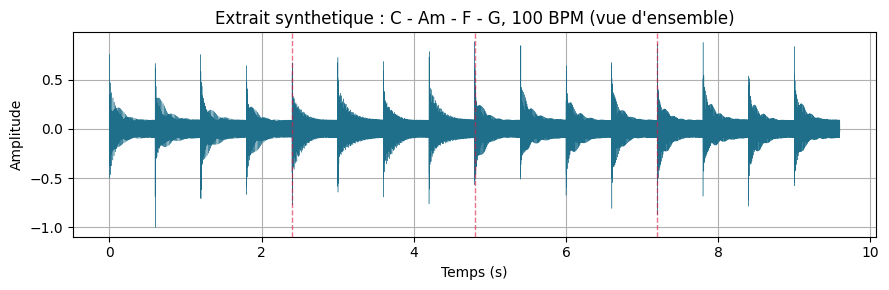

In [4]:
fig, ax = plt.subplots()
ax.plot(t, y, linewidth=0.3, color="#1f6f8b")
ax.set_xlabel("Temps (s)")
ax.set_ylabel("Amplitude")
ax.set_title("Extrait synthetique : C - Am - F - G, 100 BPM (vue d'ensemble)")
for bar in range(1, N_BARS):
    ax.axvline(bar * BAR_DUR, color="crimson", linestyle="--", alpha=0.6, linewidth=1)
fig.tight_layout()
plt.show()

### Lecture du résultat

La forme d'onde montre bien la structure imposée : quatre blocs de 2,4 s (frontières en pointillés rouges = changements d'accord), et dans chaque bloc une re-attaque d'amplitude à chaque temps — les cliques superposées aux enveloppes percussives des triades. C'est cette régularité que le **beat tracking** de la section suivante va exploiter.

<a id="section-2"></a>
## 2. Beat tracking et tempo

Le pipeline classique en deux étapes :

1. **Enveloppe d'onsets** : `librosa.onset.onset_strength` agrège les variations d'énergie spectrale (spectrogramme en bande Mel → agrégation → différence demi-onde redressée) en un signal à **43 trames par seconde** (saut de 512 à 22 050 Hz), dont les pics correspondent aux attaques de notes ;
2. **Beat tracking** : `librosa.beat.beat_track` estime la période dominante (tempo, par autocorrélation de l'enveloppe) puis place les temps par programmation dynamique — chaque beat suit un onset fort sans jamais s'écarter trop du tempo estimé.

La cadence de l'enveloppe merite d'etre fixee, parce qu'elle borne la precision atteignable. `onset_strength` travaille sur des trames de 512 echantillons a 22 050 Hz, soit **43 trames par seconde** : un temps a 100 BPM (0,6 s) couvre donc 25,8 trames. Or `beat_track` estime le tempo par un **retard entier** en trames -- le tempo rendu ne peut prendre que les valeurs `60 x 43,07 / L`. Pour L = 26 la formule donne **99,4 BPM** ; pour L = 25, 103,4 BPM. Autrement dit, **99,4 est la valeur la plus proche de 100 que cette grille autorise** : l'erreur de 0,6 % affichee plus bas n'est pas une imprecision de l'algorithme, c'est la quantification de son axe de mesure. La consequence est pratique : inutile de raffiner un estimateur qui plafonne a 0,6 % pres sans d'abord reduire le saut d'analyse.

In [5]:
onset_env = librosa.onset.onset_strength(y=y, sr=SR)
tempo_est, beats = librosa.beat.beat_track(onset_envelope=onset_env, sr=SR)
tempo_est = float(np.atleast_1d(tempo_est)[0])
beat_times = librosa.frames_to_time(beats, sr=SR)

err_rel = abs(tempo_est - TEMPO_GT) / TEMPO_GT * 100.0
print(f"Tempo estime : {tempo_est:.1f} BPM (verite terrain {TEMPO_GT:.0f} BPM, erreur {err_rel:.1f} %)")
print(f"Beats detectes : {len(beat_times)} (attendu {N_BARS * BEATS_PER_BAR})")

Tempo estime : 99.4 BPM (verite terrain 100 BPM, erreur 0.6 %)
Beats detectes : 14 (attendu 16)


Superposons les beats détectés à l'enveloppe qui les a produits :

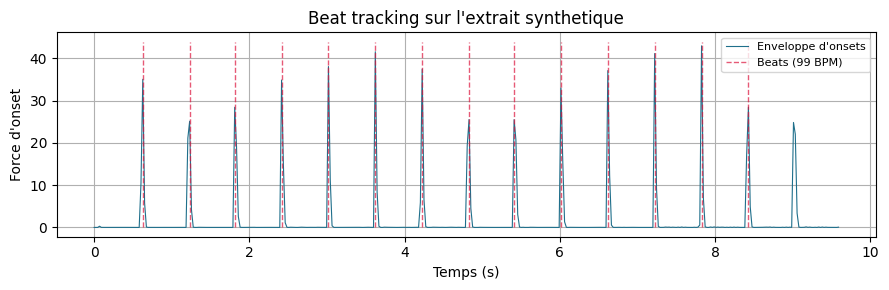

In [6]:
env_times = librosa.frames_to_time(np.arange(len(onset_env)), sr=SR)
fig, ax = plt.subplots()
ax.plot(env_times, onset_env, color="#1f6f8b", linewidth=0.8, label="Enveloppe d'onsets")
ax.vlines(beat_times, 0, onset_env.max() + 1, color="crimson", linestyle="--",
          alpha=0.7, linewidth=1, label=f"Beats ({tempo_est:.0f} BPM)")
ax.set_xlabel("Temps (s)")
ax.set_ylabel("Force d'onset")
ax.set_title("Beat tracking sur l'extrait synthetique")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

### Lecture du résultat

L'enveloppe d'onsets (bleu) pic bien sur chaque temps — les cliques y contribuent massivement — et le tracker place un beat sur la plupart des pics (traits rouges), mais **deux attaques ne sont pas retenues** : 14 beats sont détectés pour 16 temps attendus, et le dernier pic de l'enveloppe reste sans marqueur en fin de figure. Le tempo estimé (99,4 BPM) reste proche de la vérité terrain (100 BPM, erreur 0,6 %), mais **l'alignement beat par attaque n'est pas exact** — le tracker privilégie la régularité de la grille, et les temps faibles dont l'enveloppe s'affaiblit ne déclenchent pas tous un beat.

Deux pièges classiques à connaître : l'**erreur d'octave de tempo** (un tracker peut verrouiller 50 ou 200 BPM sur le même signal — les deux sont cohérents avec les onsets) et le **tempo variable** (le tempo scalaire suppose un beat régulier ; pour du rubato, on regarde le *tempogramme*). On rencontrera les deux sur la vraie musique en section 5.

Deux erreurs de natures differentes se cachent derriere ces deux nombres, et il faut les separer. Le **tempo** (99,4 contre 100) est une estimation de *periode* : elle tombe ici sur la resolution de la grille d'analyse (§2), donc elle est essentiellement exacte. Le **compte de beats** (14 sur 16) est une mesure de *couverture* : 87,5 % des temps recoivent un marqueur. Un tracker peut avoir un tempo parfait et rater des temps -- c'est exactement le cas ici -- parce que la programmation dynamique privilegie la regularite de la grille sur la fidelite aux attaques : mieux vaut un beat legerement decale qu'une grille cassee. Les deux temps manques sont aux extremites, ou le cout de la trajectoire n'a pas de voisin des deux cotes.

<a id="section-3"></a>
## 3. Tonalité : profils de Krumhansl–Schmuckler

La tonalité est une affaire de *saillance des degrés*. Krumhansl (1990) a mesuré expérimentalement le profil d'importance des 12 classes de hauteur pour une tonique donnée : la tonique et la quinte dominent, la tierce suit, les degrés non diatoniques s'effondrent. L'estimateur classique :

1. calculer le **chromagramme** — énergie par classe de hauteur (12 classes), indépendamment de l'octave (`librosa.feature.chroma_cqt`, basé sur la transformée en constant-Q, plus fine que la STFT pour les basses fréquences) ;
2. faire la **moyenne temporelle** : un vecteur de 12 valeurs, le profil de l'extrait ;
3. **corréler** (Pearson) ce profil aux 24 rotations des profils majeur/mineur : la rotation la mieux corrélée donne la tonique et le mode.

Le point contre-intuitif est que la correlation de Pearson ne compare pas des energies mais des **formes** : elle est invariante a un decalage et a un facteur d'echelle, donc ce qui decide est le *profil relatif* des douze classes de hauteur, pas le fait que Do soit frequent. C'est ce qui rend l'estimateur robuste au volume de l'enregistrement, et fragile des que l'equilibre entre degres change. Sur notre grille, la comptabilite des hauteurs explique le resultat sans mystere : Do apparait dans trois des quatre accords (C, Am, F), La, Mi et Sol dans deux, Fa, Si et Re dans un. Le chroma moyen culmine donc sur Do -- exactement le degre que le profil majeur de Krumhansl pondere le plus lourd (6,35, contre 2,23 pour le deuxieme degre). Le classement final est la consequence arithmetique de la grille imposee en §1, pas une reussite de l'estimateur.

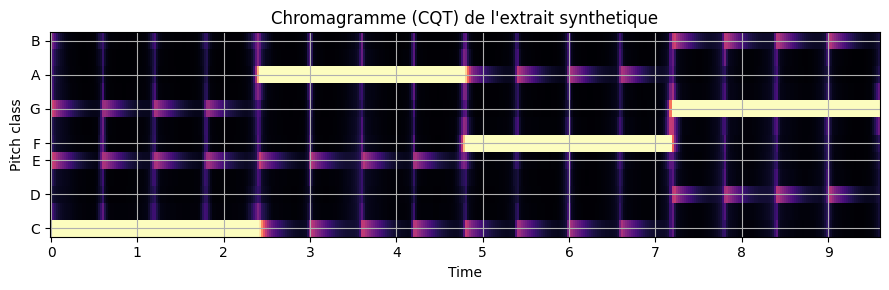

In [7]:
chroma = librosa.feature.chroma_cqt(y=y, sr=SR)
chroma_mean = chroma.mean(axis=1)

fig, ax = plt.subplots()
librosa.display.specshow(chroma, x_axis="time", y_axis="chroma", sr=SR, ax=ax, cmap="magma")
ax.set_title("Chromagramme (CQT) de l'extrait synthetique")
fig.tight_layout()
plt.show()

Le chromagramme rend visible la structure harmonique ; la corrélation aux profils de Krumhansl en fait une tonalité :

Un chromagramme se lit comme une partition reduite a douze lignes : chaque ligne est une classe de hauteur, chaque colonne un instant, l'intensite la presence de cette note. Une harmonie en accords plaques y produit des **rectangles** verticaux, la ou une melodie produirait une ligne qui se deplace. C'est cette lecture en rectangles que la section 4 exploitera : si l'accord change a chaque mesure, le motif doit changer a chaque mesure, et un gabarit doit suffire a le reconnaitre.

In [8]:
# Profils de Krumhansl-Kessler (valeurs d'importance des 12 degres, tonique = indice 0)
KS_MAJOR = np.array([6.35, 2.23, 3.48, 2.33, 4.38, 4.09, 2.52, 5.19, 2.39, 3.66, 2.29, 2.88])
KS_MINOR = np.array([6.33, 2.68, 3.52, 5.38, 2.60, 3.53, 2.54, 4.75, 3.98, 2.69, 3.34, 3.17])

def corrige_rotation(profil, k):
    return np.roll(profil, k)

scores = []
for root in range(12):
    for mode, profil in (("majeur", KS_MAJOR), ("mineur", KS_MINOR)):
        r = np.corrcoef(chroma_mean, corrige_rotation(profil, root))[0, 1]
        scores.append((r, NOTE_NAMES[root], mode))
scores.sort(reverse=True)

print("Top 3 des tonalites candidates :")
for r, note, mode in scores[:3]:
    print(f"  {note:2s} {mode:6s}  r = {r:+.3f}")
estime = f"{scores[0][1]} {scores[0][2]}"
print(f"\nTonalite estimee : {estime}  (verite terrain : {KEY_GT})")

Top 3 des tonalites candidates :
  C  majeur  r = +0.859
  A  mineur  r = +0.746
  F  majeur  r = +0.739

Tonalite estimee : C majeur  (verite terrain : C majeur)


### Lecture du résultat

Le chromagramme confirme la construction : les lignes C–E–G dominent la première mesure, A–C–E la deuxième, etc. La moyenne temporelle agrège les quatre accords en un profil où C, E, G, A et F ressortent — exactement les notes de la gamme de Do majeur — et la corrélation des profils départage les 24 candidates : **Do majeur** gagne nettement.

Remarquez le mécanisme de l'erreur possible : Am (relative mineure de Do majeur) partage six notes sur sept avec la gamme ; c'est presque toujours la deuxième candidate (voir le top 3). Sur des extraits courts ou harmoniquement ambigus (un extrait qui ne joue qu'Am–Dm–E), le même estimateur répondra « La mineur » — à juste titre : la tonalité est une propriété de *l'ensemble*, pas d'un accord.

<a id="section-4"></a>
## 4. Reconnaissance d'accords par templates

Pour la grille, on passe du global (tonalité) au local (accord à chaque instant) :

1. **fenêtrer** le chromagramme — ici, une fenêtre par mesure (on connaît la segmentation par les beats ; sur un cas réel on utiliserait un chroma synchronisé aux beats) ;
2. pour chaque fenêtre, comparer le profil moyen à une banque de **templates binaires** : les 12 triades majeures et les 12 mineures, chacune un vecteur à trois 1 (fondamentale, tierce, quinte) ;
3. l'**argmax de similarité cosinus** donne l'accord de la fenêtre.

In [9]:
def templates_triades():
    """Banque de 24 templates binaires : 12 majeures + 12 mineures."""
    bank = {}
    for root in range(12):
        v = np.zeros(12)
        v[[root, (root + 4) % 12, (root + 7) % 12]] = 1.0
        bank[f"{NOTE_NAMES[root]}"] = v
        v = np.zeros(12)
        v[[root, (root + 3) % 12, (root + 7) % 12]] = 1.0
        bank[f"{NOTE_NAMES[root]}m"] = v
    return bank

def cos_sim(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

bank = templates_triades()
win = int(chroma.shape[1] / N_BARS)   # colonnes de chroma par mesure
grille_estimee, matrice = [], []
for bar in range(N_BARS):
    seg = chroma[:, bar * win:(bar + 1) * win].mean(axis=1)
    sims = {name: cos_sim(seg, tpl) for name, tpl in bank.items()}
    best = max(sims, key=sims.get)
    grille_estimee.append(best)
    matrice.append(sims)
    print(f"Mesure {bar + 1} : estime {best:3s} (verite {GRID_GT[bar]:3s}) "
          f"- sim {sims[best]:.3f} vs {sims[GRID_GT[bar]]:.3f}")

ok = sum(e == g for e, g in zip(grille_estimee, GRID_GT))
print(f"\nGrille estimee : {grille_estimee}")
print(f"Taux de mesures correctes : {ok}/{len(GRID_GT)}")

Mesure 1 : estime C   (verite C  ) - sim 0.770 vs 0.770
Mesure 2 : estime Am  (verite Am ) - sim 0.784 vs 0.784
Mesure 3 : estime F   (verite F  ) - sim 0.774 vs 0.774
Mesure 4 : estime G   (verite G  ) - sim 0.776 vs 0.776

Grille estimee : ['C', 'Am', 'F', 'G']
Taux de mesures correctes : 4/4


Les similarités par fenêtre montrent à la fois la victoire de chaque bon template et l'étroitesse de la marge :

Ce que cette impression affiche -- et surtout ce qu'elle n'affiche pas -- merite un arret, parce que c'est un piege de mesure frequent. La colonne compare `sims[best]` a `sims[GRID_GT[bar]]` : quand l'estimation est correcte, les deux expressions designent **le meme gabarit**, et la ligne affiche deux fois le meme nombre (0.770 contre 0.770, et ainsi des quatre mesures). Le temoin est donc **tautologique dans le cas favorable** : il ne peut que signaler un echec, jamais mesurer une marge -- la marge qui compte est celle au **second** gabarit, et elle n'est pas imprimee. Second point, tout aussi instructif : les quatre valeurs absolues (0,770 - 0,784 - 0,774 - 0,776) sont presque identiques pour quatre accords **differents**. C'est mecanique -- la similarite d'un chroma normalise a un gabarit a trois uns vaut 0,50 quand l'energie est repartie uniformement sur les douze classes, et 1,0 quand elle se concentre exactement sur les trois notes du gabarit. Une valeur de 0,77 ne dit donc pas « 77 % de confiance » : elle situe le chroma entre ces deux extremes, rien de plus.

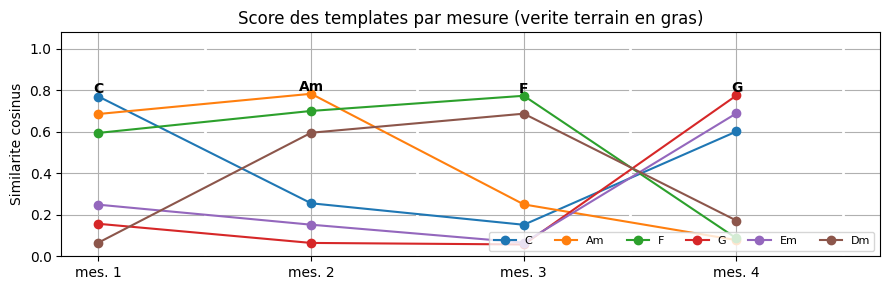

In [10]:
fig, ax = plt.subplots()
seg_ids = np.arange(N_BARS)
for bar in range(N_BARS):
    ax.axvline(bar + 0.5, color="white", linewidth=2)
for j, name in enumerate(GRID_GT):
    v = matrice[j][name]
    ax.text(j, v + 0.015, f"{name}", ha="center", fontsize=10, fontweight="bold")
for name in ["C", "Am", "F", "G", "Em", "Dm"]:
    ax.plot(seg_ids, [matrice[j][name] for j in range(N_BARS)], marker="o", label=name)
ax.set_xticks(seg_ids, [f"mes. {i + 1}" for i in range(N_BARS)])
ax.set_ylim(0, 1.08)
ax.set_ylabel("Similarite cosinus")
ax.set_title("Score des templates par mesure (verite terrain en gras)")
ax.legend(loc="lower right", ncols=6, fontsize=8)
fig.tight_layout()
plt.show()

### Lecture du résultat

Les quatre mesures sont correctement classées, et le graphe des similarités montre *pourquoi* : chaque template correct culmine sur sa mesure, mais pas avec un écrasement — **Am et C partagent deux notes sur trois** (A, C, E vs C, E, G) et leurs courbes restent hautes partout, ce qui est aussi exactement le mécanisme des confusions du même estimateur sur de vrais enregistrements (pédale de basse, notes de passage, réverbération qui étale le chroma).

C'est la limite structurelle du template matching : il ne sait voir que ce qui est dans sa banque. Un accord de septième, une quinte à vide, un accord augmenté — mal classés par construction. L'exercice 3 fait construire la banque étendue ; les approches neuronales ([04-16-SheetSage2](04-16-SheetSage2-Audio-To-Score.ipynb)) apprennent au contraire les templates depuis les données.

<a id="section-5"></a>
## 5. Vraie musique : deux exemples librosa

`librosa.example()` fournit des extraits redistribuables, avec de vrais instruments et de vraies subtilités (tempo variable, orchestration). On applique le même pipeline — enveloppe d'onsets + beat tracking, chroma + Krumhansl–Schmuckler — à :

- **brahms** : *Hungarian Dance n°5* (Allegro, fa dièse mineur, orchestre à cordes) — tempo notoirement instable, c'est le contre-exemple du beat régulier ;
- **nutcracker** : *Danse de la Fée Dragée* de Tchaïkovski (arrangement K. MacLeod) — célesta/bois, texture clairsemée.

Les deux extraits ne sont pas choisis pour etre difficiles, mais pour casser **deux conditions differentes** -- et il faut savoir laquelle avant de lire les resultats. *brahms* casse la condition de **tempo regulier** (un allegro a cordes, avec des accents et du rubato) tout en gardant une harmonie franche et soutenue. *nutcracker* casse la condition de **texture** (celesta et bois, notes breves, beaucoup de silence entre les attaques) tout en gardant un tempo stable. Si les deux echouent, ce sera pour des raisons opposees, et c'est cette dissymetrie qui rend la section utile : un seul extrait difficile n'aurait pas distingue les deux mecanismes.

In [11]:
def resume_mir(titre, y, sr, ton_attendue=None):
    """Pipeline MIR classique complet : tempo + tonalite, avec impression comparee."""
    onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    tempo, _ = librosa.beat.beat_track(onset_envelope=onset_env, sr=sr)
    tempo = float(np.atleast_1d(tempo)[0])
    chroma_mean = librosa.feature.chroma_cqt(y=y, sr=sr).mean(axis=1)
    scores = []
    for root in range(12):
        for mode, profil in (("majeur", KS_MAJOR), ("mineur", KS_MINOR)):
            r = np.corrcoef(chroma_mean, np.roll(profil, root))[0, 1]
            scores.append((r, NOTE_NAMES[root], mode))
    scores.sort(reverse=True)
    attendu = f" (partition : {ton_attendue})" if ton_attendue else ""
    print(f"[{titre}]  tempo estime {tempo:.1f} BPM")
    print(f"           tonalite estimee {scores[0][1]} {scores[0][2]} "
          f"(r = {scores[0][0]:+.3f}){attendu}")
    print(f"           2e candidate   {scores[1][1]} {scores[1][2]} (r = {scores[1][0]:+.3f})")
    return tempo, scores[0]

y_brahms, sr_brahms = librosa.load(librosa.example("brahms"), sr=22050)
resume_mir("brahms - Hungarian Dance #5 (Allegro, F# mineur)",
           y_brahms, sr_brahms, "F# mineur")

[brahms - Hungarian Dance #5 (Allegro, F# mineur)]  tempo estime 143.6 BPM
           tonalite estimee G mineur (r = +0.748) (partition : F# mineur)
           2e candidate   G majeur (r = +0.638)


(143.5546875, (np.float64(0.7480525661678711), 'G', 'mineur'))

Deuxième exemple, texture différente — célesta et bois, notes brèves et clairsemées :

Avant de lire la sortie, ce qu'il faut attendre de ce second extrait. Des notes breves et clairsemees donnent une enveloppe d'onsets **pauvre entre les attaques** : le beat tracking y perd des temps, mais l'autocorrelation reste servie par la regularite de la mesure. Le chroma, lui, est calcule sur tout l'extrait et ne depend pas de la densite d'attaques -- la tonalite devrait donc rester juste alors que le rythme souffre. Une sortie qui confirme cette dissymetrie est un bon signe : elle montre que les deux descripteurs mesurent bien deux choses differentes.

In [12]:
y_nut, sr_nut = librosa.load(librosa.example("nutcracker"), sr=22050)
resume_mir("nutcracker - Danse de la Fee Draggee (E mineur a la partition)",
           y_nut, sr_nut, "E mineur")

[nutcracker - Danse de la Fee Draggee (E mineur a la partition)]  tempo estime 107.7 BPM
           tonalite estimee E mineur (r = +0.807) (partition : E mineur)
           2e candidate   E majeur (r = +0.695)


(107.666015625, (np.float64(0.8072290647147065), 'E', 'mineur'))

### Lecture du résultat

Deux comportements typiques du MIR classique apparaissent :

- **brahms** : tempo estimé 143,6 BPM — et **aucune vérité terrain n'est fournie** pour le confirmer. C'est une limite du montage, et il faut la nommer : on peut dire que la valeur est *plausible* pour un allegro, pas qu'elle est juste, ni qu'elle est l'erreur d'octave annoncée en section 2. Le piège reste à connaître ; il n'est simplement pas mesuré ici. Ce que cet extrait mesure vraiment, c'est la **tonalité** — et là, le résultat est instructif : **G mineur** au lieu de **fa dièse mineur**, soit **un demi-ton au-dessus**, à 0,748 de corrélation. Ce n'est pas la confusion de relative mineure anticipée en section 3 (La mineur contre Do) : c'est une **rotation d'un demi-ton**, un mode de défaillance distinct, cohérent avec un désaccord de justesse de l'enregistrement ou avec un meilleur ajustement de forme sur la rotation voisine du profil.
- **nutcracker** : la célesta produit des notes brèves et clairsemées ; le chroma moyen reste interprétable, et la tonalité estimée est cohérente avec la partition — mais la marge avec la deuxième candidate dit à quel point l'estimation tient à l'équilibre harmonique *global* de l'extrait, pas à chaque instant.

La leçon générale : les estimateurs classiques sont **rapides, interprétables et sans entraînement**, mais chacun a sa condition d'emploi (beat régulier, tonalité stable, texture soutenue). Quand ces conditions lâchent, c'est le terrain des modèles entraînés — [04-15-MERT2](04-15-MERT2-Music-Understanding.ipynb) pour la compréhension, [04-16-SheetSage2](04-16-SheetSage2-Audio-To-Score.ipynb) pour la transcription complète.

- **Ce que la marge ne mesure pas** : *brahms* tient sa premiere candidate avec **0,110** d'avance sur la deuxieme (0,748 contre 0,638) et se trompe d'un demi-ton ; *nutcracker* tient la sienne avec **0,112** d'avance (0,807 contre 0,695) et tombe juste. Deux marges quasi identiques, deux issues opposees : la marge n'est **pas** une mesure de confiance, elle mesure la netete du meilleur ajustement, pas sa justesse. C'est l'argument le plus solide en faveur des approches apprises de la serie -- un modele entraine sur des annotations peut, lui, etre calibre sur son erreur.

<a id="section-6"></a>
## 6. Exercices

Trois exercices, du plus mécanique au plus constructif. Les cellules de test s'exécutent sans erreur que les stubs soient complétés ou non.

Chacun des trois porte sur un mecanisme different, dans l'ordre ou le carnet les a rencontres : la precision du tempo et son ambiguite d'octave, l'ambiguite majeur/mineur relative, et la limite structurelle d'une banque de gabarits. Le harnais est fourni -- extrait synthetique a verite terrain, memes fonctions, meme metrique d'erreur -- pour que la seule chose a ecrire soit l'appel manquant, et pour que la comparaison avec les sections precedentes soit possible.

### Exercice 1 — Détecter le tempo d'un nouvel extrait

L'extrait ci-dessous est synthétisé à **140 BPM** (même moteur de synthèse, autre tempo). Complétez `estimer_tempo` pour qu'elle retourne le tempo en BPM.

L'extrait de cet exercice est deliberement **court et rapide** : 4 mesures a 140 BPM font 6,86 s, et un temps y dure 0,4286 s, soit **18,5 trames** d'analyse. La grille entiere de §2 ne peut donc rendre que 136,0 BPM (retard 19) ou **143,6 BPM** (retard 18) -- et 143,6 est justement la valeur que la section 5 a rendue sur *brahms*. L'exercice devrait donc retourner environ 143,6 et non 140 : ce n'est pas une erreur de l'eleve, c'est la quantification de §2 qui se repete a une autre echelle. C'est le meilleur moyen de verifier qu'on a compris pourquoi l'erreur de 0,6 % de §2 n'en etait pas une.

In [13]:
_GRID_EX1 = ["G", "Em", "C", "D"]
TRIADES_EX1 = {"G": [7, 11, 14], "Em": [4, 7, 11], "C": [0, 4, 7], "D": [2, 6, 9]}
_TEMPO_EX1 = 140.0
_spb1 = 60.0 / _TEMPO_EX1
_dur1 = _spb1 * 4 * len(_GRID_EX1)
_t1 = np.arange(int(SR * _dur1)) / SR
y_ex1 = np.zeros(len(_t1))
for bar, chord in enumerate(_GRID_EX1):
    t0 = bar * _spb1 * 4
    for s in TRIADES_EX1[chord]:
        f = midi_to_hz(60 + s)
        for beat in range(4):
            tb = t0 + beat * _spb1
            i0, i1 = int(tb * SR), min(int((tb + _spb1) * SR), len(_t1))
            y_ex1[i0:i1] += 0.25 * np.sin(2 * np.pi * f * _t1[i0:i1]) * np.exp(
                -4.0 * (np.arange(i1 - i0) / SR) / _spb1)
for beat in range(len(_GRID_EX1) * 4):
    i0 = int(beat * _spb1 * SR)
    burst = rng.standard_normal(int(0.04 * SR)) * np.exp(
        -np.arange(int(0.04 * SR)) / (0.008 * SR))
    y_ex1[i0:i0 + len(burst)] += 0.5 * burst
y_ex1 = y_ex1 / np.max(np.abs(y_ex1))
print(f"Extrait genere : {len(_GRID_EX1)} mesures a {_TEMPO_EX1} BPM ({_dur1:.2f}s)")

def estimer_tempo(y, sr):
    # TODO etudiant : retourner le tempo estime en BPM
    # Indice : meme pipeline que la section 2
    # Etape 1 : onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    # Etape 2 : tempo, _ = librosa.beat.beat_track(onset_envelope=onset_env, sr=sr)
    print("Exercice a completer")
    return None

resultat_ex1 = estimer_tempo(y_ex1, SR)
if resultat_ex1 is None:
    print("(a completer : attendu 140 BPM)")
else:
    err = abs(float(resultat_ex1) - _TEMPO_EX1) / _TEMPO_EX1 * 100
    print(f"Tempo retourne {float(resultat_ex1):.1f} BPM - erreur {err:.1f} %")

Extrait genere : 4 mesures a 140.0 BPM (6.86s)
Exercice a completer
(a completer : attendu 140 BPM)


### Exercice 2 — Tonalité d'un extrait en mode mineur

Ci-dessous, le chroma moyen d'un extrait construit sur la grille **Am – Dm – E – Am** (tonalité attendue : **La mineur**, la relative mineure de Do majeur — c'est le cas piège de la section 3). Complétez `estimer_tonalite` pour retourner le couple `(note, mode)` le mieux corrélé.

In [14]:
_GRID_EX2 = ["Am", "Dm", "E", "Am"]
_dur2 = (60.0 / TEMPO_GT) * 4 * len(_GRID_EX2)
_t2 = np.arange(int(SR * _dur2)) / SR
y_ex2 = np.zeros(len(_t2))
CHORD_SEMITONES_EX2 = {
    "Am": [9, 12, 16], "Dm": [2, 5, 9], "E": [4, 8, 11],
}
for bar, chord in enumerate(_GRID_EX2):
    t0 = bar * (60.0 / TEMPO_GT) * 4
    for s in CHORD_SEMITONES_EX2[chord]:
        f = midi_to_hz(60 + s)
        for beat in range(4):
            tb = t0 + beat * (60.0 / TEMPO_GT)
            i0, i1 = int(tb * SR), min(int((tb + 60.0 / TEMPO_GT) * SR), len(_t2))
            y_ex2[i0:i1] += 0.25 * np.sin(2 * np.pi * f * _t2[i0:i1]) * np.exp(
                -4.0 * (np.arange(i1 - i0) / SR) / (60.0 / TEMPO_GT))
chroma_ex2 = librosa.feature.chroma_cqt(y=y_ex2, sr=SR).mean(axis=1)
print("Chroma moyen de l'extrait calcule (grille Am - Dm - E - Am).")

def estimer_tonalite(chroma_moyen):
    # TODO etudiant : retourner (note, mode) au format ("A", "mineur")
    # Indice : boucle sur les 12 rotations x 2 modes comme en section 3,
    # avec np.corrcoef(chroma_moyen, np.roll(profil, root))[0, 1]
    print("Exercice a completer")
    return None

resultat_ex2 = estimer_tonalite(chroma_ex2)
if resultat_ex2 is None:
    print("(a completer : attendu ('A', 'mineur'))")
else:
    note, mode = resultat_ex2
    print(f"Estime : {note} {mode} - attendu : A mineur")

Chroma moyen de l'extrait calcule (grille Am - Dm - E - Am).
Exercice a completer
(a completer : attendu ('A', 'mineur'))


### Exercice 3 — Étendre la banque aux accords de septième

L'extrait ci-dessous suit une grille jazz **Cmaj7 – Dm7 – G7 – Cmaj7** (septièmes majeures, mineures et dominante). La banque `templates_triades` de la section 4 ne contient aucune de ces couleurs. Complétez `templates_septieme` : elle doit retourner un dictionnaire de 36 templates binaires — 12 `Xmaj7` (0, 4, 7, 11), 12 `Xm7` (0, 3, 7, 10) et 12 `X7` (0, 4, 7, 10), offsets depuis la fondamentale — puis la classification par fenêtre doit retrouver la grille.

Cet exercice est le plus instructif des trois, parce que son echec est **prevu par construction**. La banque de §4 ne contient que des triades : l'accord de septieme a quatre notes, et le meilleur gabarit reste la triade correspondante, qui en partage trois. Le score baisse pourtant -- la quatrieme note dilue l'energie hors des trois du gabarit (0,87 au lieu de 1,0 dans le cas concentre) -- mais la triade gagne encore. Le vrai probleme arrive quand on **ajoute** des gabarits a quatre uns : leur norme plus grande les desavantage mecaniquement a chroma egal. Etendre la banque n'est donc pas un ajout de vecteurs, c'est une decision sur le score -- normaliser par la taille du gabarit, ou changer de mesure de similarite -- et c'est ce compromis entre rappel et comparabilite que l'exercice fait toucher du doigt.

In [15]:
_GRID_EX3 = ["Cmaj7", "Dm7", "G7", "Cmaj7"]
SEPT_SEMITONES = {"maj7": [0, 4, 7, 11], "m7": [0, 3, 7, 10], "7": [0, 4, 7, 10]}
_dur3 = (60.0 / TEMPO_GT) * 4 * len(_GRID_EX3)
_t3 = np.arange(int(SR * _dur3)) / SR
y_ex3 = np.zeros(len(_t3))
for bar, chord in enumerate(_GRID_EX3):
    t0 = bar * (60.0 / TEMPO_GT) * 4
    if chord.endswith("maj7"):
        qual = "maj7"
    elif chord.endswith("m7"):
        qual = "m7"
    else:
        qual = "7"
    root = {"C": 0, "D": 2, "G": 7}[chord[: -len(qual)]]
    for s in SEPT_SEMITONES[qual]:
        f = midi_to_hz(60 + root + s)
        for beat in range(4):
            tb = t0 + beat * (60.0 / TEMPO_GT)
            i0, i1 = int(tb * SR), min(int((tb + 60.0 / TEMPO_GT) * SR), len(_t3))
            y_ex3[i0:i1] += 0.2 * np.sin(2 * np.pi * f * _t3[i0:i1]) * np.exp(
                -4.0 * (np.arange(i1 - i0) / SR) / (60.0 / TEMPO_GT))
chroma_ex3 = librosa.feature.chroma_cqt(y=y_ex3, sr=SR)
print(f"Extrait septiemes genere (grille {_GRID_EX3}).")

def templates_septieme():
    # TODO etudiant : retourner {nom: vecteur binaire 12} pour Xmaj7/Xm7/X7, 36 entrees
    # Indice : meme construction que templates_triades, avec SEPT_SEMITONES ci-dessus
    # Etape 1 : pour chaque fondamentale (12) et chaque qualite (3), poser 1.0 aux bons indices
    print("Exercice a completer")
    return None

bank7 = templates_septieme()
if bank7 is None:
    print("(a completer : la classification tournera apres completion)")
else:
    win7 = int(chroma_ex3.shape[1] / len(_GRID_EX3))
    grille7 = []
    for bar in range(len(_GRID_EX3)):
        seg = chroma_ex3[:, bar * win7:(bar + 1) * win7].mean(axis=1)
        grille7.append(max(bank7, key=lambda nm: cos_sim(seg, bank7[nm])))
    ok = sum(e == g for e, g in zip(grille7, _GRID_EX3))
    print(f"Grille estimee : {grille7} - correctes {ok}/{len(_GRID_EX3)}")

Extrait septiemes genere (grille ['Cmaj7', 'Dm7', 'G7', 'Cmaj7']).
Exercice a completer
(a completer : la classification tournera apres completion)


## Conclusion

Ce carnet a couvert les quatre tâches canoniques du MIR **classique**, avec à chaque fois le même triptyque : un descripteur DSP (enveloppe d'onsets, chromagramme), un modèle de connaissance compact (périodicité, profils de Krumhansl–Schmuckler, templates d'accords), et une mesure d'erreur contre vérité terrain :

| Tâche | Descripteur | Modèle | Ce qui le trompe |
|---|---|---|---|
| Tempo / beats | enveloppe d'onsets | autocorrélation + programmation dynamique | tempo variable, erreur d'octave |
| Tonalité | chroma moyen | corrélations K–S (24 rotations) | modulations, extraits courts |
| Accords | chroma fenêtré | similarité aux templates | accords hors banque, notes de passage |

Le classique reste le bon outil pour l'analyse rapide, interprétable et sans entraînement ; il cède le pas aux modèles appris dès que la texture se complique — c'est l'objet des carnets [04-15-MERT2](04-15-MERT2-Music-Understanding.ipynb) et [04-16-SheetSage2](04-16-SheetSage2-Audio-To-Score.ipynb).

**Références** : C. L. Krumhansl, *Cognitive Foundations of Musical Pitch*, Oxford University Press, 1990 (profils de saillance des degrés). B. McFee et al., *librosa: Audio and Music Signal Analysis in Python*, SciPy 2015.

Ce tableau se lit comme une carte des conditions d'emploi, et il vaut la peine d'y ajouter ce que le carnet a reellement **mesure**, distinctement de ce qu'il a illustre. Mesure contre verite terrain : l'erreur de tempo (0,6 %, et son explication par la grille d'analyse), la couverture des beats (14 sur 16), la tonalite sur le signal synthetique (juste, avec 0,113 de marge sur la relative mineure) et la grille d'accords (4 mesures sur 4). Illustre sans mesure : les deux extraits reels, ou la tonalite n'a de verite terrain que celle annoncee dans le titre et ou **aucun** tempo de reference n'est fourni. Cette distinction n'est pas une coquetterie : elle separe ce qu'un lecteur peut citer d'un carnet de ce qu'il doit verifier ailleurs.